##### Command de instaler libs :
- pip install numpy matplotlib seaborn scikit-learn opencv-python kaggle
- mlflow

In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import cv2

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import f1_score

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Dense
from tensorflow.keras.callbacks import ModelCheckpoint, BackupAndRestore, EarlyStopping
from tensorflow.keras.utils import to_categorical
import mlflow
import mlflow.tensorflow
import kagglehub

RANDOM_KEY=26
SIZE_IMAGE=224
BATCH_SIZE = 45
EPOCHS = 10
AUTOTUNE = tf.data.AUTOTUNE

DATA_DIR = Path(kagglehub.dataset_download("hamzahajjaji/brief-5-dataset") + '/Data')
print(DATA_DIR)

/kaggle/input/datasets/hamzahajjaji/brief-5-dataset/Data


#### Charger les images

In [9]:
def loead_images(data_dire:str):
    images = []
    labels = []

    extention_allow = {".jpeg", ".jpg", ".bmp", ".png"}

    for folder in Path(data_dire).iterdir():
        if not folder.is_dir():
            continue

        label = folder.name

        for file in folder.iterdir():
            if file.suffix.lower() not in extention_allow:
                continue

            images.append(str(file))
            labels.append(label)
    return images, labels

images_path, labels = loead_images(DATA_DIR)


print("Nomber d'images :", len(images_path))
print("Nomber de labels :", len(labels))

print('Example de image:', images_path[0])
print('Example de Label:', labels[0])

Nomber d'images : 7023
Nomber de labels : 7023
Example de image: /kaggle/input/datasets/hamzahajjaji/brief-5-dataset/Data/glioma/Te-glTr_0000.jpg
Example de Label: glioma


#### Convertir les listes en tableaux NumPy

In [10]:
def convert_to_numpay_table(images, labels):
    return np.array(images), np.array(labels)

X, y = convert_to_numpay_table(images_path, labels)

#### Afficher un échantillon d'images

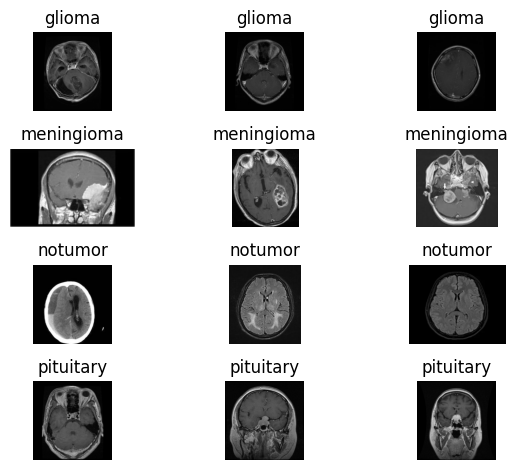

In [11]:
def afficher_images_echntillon(images, labels):
    classes = np.unique(labels)
    _, axes = plt.subplots(len(classes), 3)

    for i, classe in enumerate(classes):
        images_index = np.where(labels == classe)[0][:3]
        for j, index in enumerate(images_index):
            # loead et converter BGR to RGB
            image = cv2.cvtColor(cv2.imread(images[index]), cv2.COLOR_BGR2RGB)
            axes[i, j].imshow(image)
            axes[i, j].set_title(classe)
            axes[i, j].axis('off')
    plt.tight_layout()
    plt.show()

classes = np.unique(y)

afficher_images_echntillon(X, y)

#### Afficher la distribution et l'équilibre des images

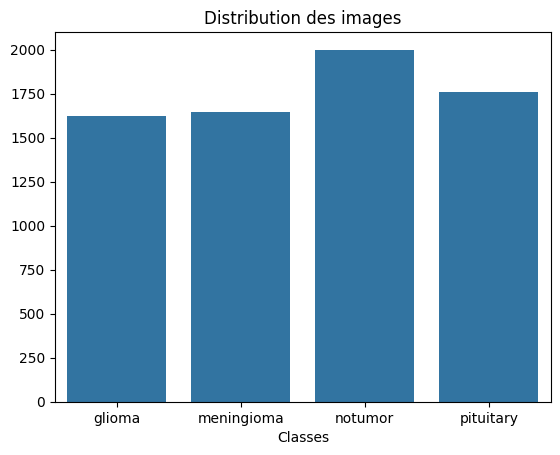

In [12]:
def afficher_distribution_classes(labels):
    classes, counts = np.unique(labels, return_counts=True)
    plt.figure()
    sns.barplot(x=classes, y=counts)
    plt.title('Distribution des images')
    plt.xlabel('Classes')
    plt.show()

afficher_distribution_classes(y)

#### Appliquer Label Encoging 

In [13]:
def applay_encoding(list):
    encoder = LabelEncoder()
    return encoder.fit_transform(list), encoder

y_encoder, label_encoder = applay_encoding(y)

num_classes = len(np.unique(y_encoder))

print(num_classes)

4


#### Split data

In [14]:
# Split test and train
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y_encoder, 
    test_size=0.3,
    stratify=y_encoder,
    random_state=RANDOM_KEY
)

# Split validation
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.2,
    stratify=y_temp,
    random_state=RANDOM_KEY
)

print("Train :", len(X_train))
print("Validation :", len(X_val))
print("Test :", len(X_test))

Train : 3932
Validation : 984
Test : 2107


#### Appliquer One-Hot Encoding

In [15]:
y_train = to_categorical(y_train, num_classes=num_classes)
y_val = to_categorical(y_val, num_classes=num_classes)
y_test = to_categorical(y_test, num_classes=num_classes)

#### TensorFlow Dataset

In [16]:
# Create dataset avec params
def create_dataset(x_data, y_data, normalize_collback, is_use_shuffle = False, is_use_augmentation = False):
    dataset = (
        tf.data.Dataset
            .from_tensor_slices((x_data, y_data))
            .map(
                lambda image_path, label: load_image(image_path, label, normalize_collback),
                num_parallel_calls=AUTOTUNE
            )
    )

    # Shuffle les donnes
    if is_use_shuffle:
        dataset.shuffle(
            buffer_size=len(x_data), # pour utiliser tout les donnes dans mélange
            seed=RANDOM_KEY # Randomize logic
        )

    # Appliquer data augmentation s'est difiner
    if is_use_augmentation:
        data_augmentation = Sequential([
            layers.RandomRotation(0.03),
            layers.RandomZoom(0.1),
            layers.RandomTranslation(
                height_factor=0.05,
                width_factor=0.05
            )
        ]) 

        dataset.map(
            lambda image, label: (data_augmentation(image), label),
            num_parallel_calls=AUTOTUNE
        )

    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE) # Pour preparer les batch en paralille


# Load image and resize and normalize
def load_image(filename, label, normalize_collback):
    # load image
    raw = tf.io.read_file(filename)

    # converter image à matric de tensors avec 3 channels
    image = tf.image.decode_image(raw, channels=3)
    image.set_shape([None, None, 3]) # Déclarer le size image pour éviter error
    
    # Resize
    image = tf.image.resize(image, [SIZE_IMAGE, SIZE_IMAGE])

    # Normalization pour Base model
    image  = normalize_collback(image)
    return image, label

#### Visualiser les courbes d'apprentissage

In [ ]:
def afficher_courbes_apprentissage(trensfoer_history, fine_tuning_history):
    # Accuracy
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    # Trensfoer Learning
    plt.plot(trensfoer_history["accuracy"], label="TL - Train")
    plt.plot(trensfoer_history["val_accuracy"], label="TL - Validation")

    # Fine-Tuning
    plt.plot(fine_tuning_history["accuracy"], label="FT - Train")
    plt.plot(fine_tuning_history["val_accuracy"], label="FT - Validation")

    plt.title("Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    # Loss
    plt.subplot(1, 2, 2)
    # Trensfoer Learning
    plt.plot(trensfoer_history["loss"], label="TL - Train")
    plt.plot(trensfoer_history["val_loss"], label="TL - Validation")

    # Fine-Tuning
    plt.plot(fine_tuning_history["loss"], label="FT - Train")
    plt.plot(fine_tuning_history["val_loss"], label="FT - Validation")

    plt.title("Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

In [ ]:
def build_transfer_model(base_model, normalize_collback, x_train, y_train, x_val, y_val, x_test,y_test):
    run_name = f'{base_model.name}_run'
    with mlflow.start_run(run_name=run_name) as run:
        run_id = run.info.run_id
        print(f"\n--- Début du Run : {run_name} (ID: {run_id}) ---")

        # Log params
        mlflow.log_param("batch_size", BATCH_SIZE)
        mlflow.log_param("epochs", EPOCHS)
        mlflow.log_param("image_size", SIZE_IMAGE)

        # ========== Dataset ==========
        # Trian
        train_ds = create_dataset(x_train, y_train, normalize_collback= normalize_collback, is_use_shuffle=True, is_use_augmentation=True)

        # Validation 
        val_ds = create_dataset(x_val, y_val, normalize_collback)

        # Test
        test_ds = create_dataset(x_test, y_test, normalize_collback)

        # charger base model pour trefer learning
        base = base_model(
            weights='imagenet', # loader les weights of train imagenet
            include_top=False, # remove classes of predicts base
            input_shape=(SIZE_IMAGE, SIZE_IMAGE, 3) # Size of input
        )

        base.trainable = False # franze all parametres of base model to not chnager on training

        # Dosser de model
        model_path = f'models/{base.name}'
        Path(model_path).mkdir(parents=True, exist_ok=True)

        # callbacks
        callbacks = [
            # Suvgarder le baset model pendant le training
            ModelCheckpoint(
                filepath=f"{model_path}/best_model.keras", # path de bast model
                monitor="val_loss", # monitore de comparisent
                save_best_only=True, # Sauvgarder le baset model sulment
                mode="min", # Suavgarder le model de min monitor
                verbose=1 # afficher sur terminal
            ),
            # Sauvgarder le étap de train si ariter pour pas perdet le étap de training
            BackupAndRestore(
                backup_dir=f"{model_path}/training_backup" # dosser de sauvgarder
            ),
            # Limiter le surapprentissage
            EarlyStopping(
                monitor="val_loss", # monitore de comparisent
                patience=5, # nomber des epochs sans augmentation de monitor
                restore_best_weights=True, # returner baset weights
                mode="min", # minimuent monitor
                verbose=1
            )
        ]

        # Model Archetecteur
        model = Sequential([
            base, # base model
            GlobalAveragePooling2D(), # minimizer les Featurs Map à vectore 

            # hiden layer
            Dense(128, activation="relu"),
            Dropout(0.3),

            # Output layer
            Dense(4, activation="softmax")
        ])

        model.summary()

        # =============== Transfer learning ===============
        # Config 
        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), # Optimizer avec learninig rate
            loss="categorical_crossentropy",
            metrics=["accuracy"]
        )

        # Train
        start_time = time.time()

        trensfoer_history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=EPOCHS,
            callbacks=callbacks
        )

        train_time = time.time() - start_time

        # Loger sur mlflow
        mlflow.log_metric("training_duration_on_TL_seconds", train_time)

        print(f"Temps d'entraînement en Trensfor learning : {train_time / 60:.2f} minute")

        # =============== Fine Tuning ===============
        # Active with parametres Trainable
        base.trainable = True
        for layer in base.layers[:-30]:
            layer.trainable = False # Frazer tout les layers de 0 jusqua dérnier 30 layers

        # Reconfig model
        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001), # Optimizer avec learninig rate tres petit
            loss="categorical_crossentropy",
            metrics=["accuracy"]
        )

        # Train
        start_time = time.time()

        fine_tuning_history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=EPOCHS,
            callbacks=callbacks  
        )

        train_time = time.time() - start_time

        # Loger sur mlflow
        mlflow.log_metric("training_duration_on_FT_seconds", train_time)
        
        print(f"Temps d'entraînement en Fine tuning : {train_time / 60:.2f} minute")

        # Visualiser les courbes d'apprentissage
        afficher_courbes_apprentissage(trensfoer_history.history, fine_tuning_history.history)

        # Préduction
        y_pred_probs = model.predict(test_ds, verbose=0) # Probabiliter sur les 4 classes
        # print(y_pred_probs[0])
        y_pred = np.argmax(y_pred_probs, axis=1) # index de max proba sur les column 
        y_true = np.argmax(y_test, axis=1) # convert One hot encoding à label encoded

        # Évaluer le modèle avec test dataset
        test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
        f1 = f1_score(y_true, y_pred)

        # Logger les métriques finales
        mlflow.log_metric("test_loss", test_loss)
        mlflow.log_metric("test_accuracy", test_accuracy)
        mlflow.log_metric("test_f1_score", f1)

        print(f"Résultats -> Loss: {test_loss:.4f} | Accuracy: {test_accuracy:.4f} | F1-score: {f1:.4f}")

        # Évaluer les prédictions avec la Confusion Matrix
        classes = label_encoder.classes_

        cm = confusion_matrix(
            y_true, 
            y_pred,
            labels=np.arange(len(classes))
        )

        display = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=classes
        )

        display.plot(cmap="Blues", xticks_rotation=45)
        plt.title("Matrice de confusion")
        plt.tight_layout()
        plt.show()

        # Loger model à artifact
        mlflow.tensorflow.log_model(
            model=model,
            artifact_path="model",
            registered_model_name=base.name
        )


#### Configurer l'expérience MLflow

In [ ]:
mlflow.set_experiment('brief_5_experiment')

# Activer l'autologging MLflow pour TensorFlow
mlflow.tensorflow.autolog()

#### MobileNetV2

I0000 00:00:1792703846.260945     114 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792703846.265646     114 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

...

87/88 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.7127 - loss: 0.7534

2026-10-22 21:20:07.832072: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 21:20:07.979464: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 21:20:08.116441: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7138 - loss: 0.7509

2026-10-22 21:20:53.564023: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 21:20:53.700801: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_loss improved from None to 0.32689, saving model to models/Functional/best_model.keras

Epoch 1: finished saving model to models/Functional/best_model.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 207s 2s/step - accuracy: 0.8021 - loss: 0.5346 - val_accuracy: 0.8669 - val_loss: 0.3269
Epoch 2/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.8873 - loss: 0.3282
Epoch 2: val_loss improved from 0.32689 to 0.26483, saving model to models/Functional/best_model.keras

Epoch 2: finished saving model to models/Functional/best_model.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 6s 63ms/step - accuracy: 0.8901 - loss: 0.3143 - val_accuracy: 0.9004 - val_loss: 0.2648
Epoch 3/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.9152 - loss: 0.2400
Epoch 3: val_loss improved from 0.26483 to 0.23969, saving model to models/Functional/best_model.keras

Epoch 3: finished saving model to models/Functional/best_model.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 6s 63ms/step - accuracy: 0.9184 - loss: 0.2319 - val_a

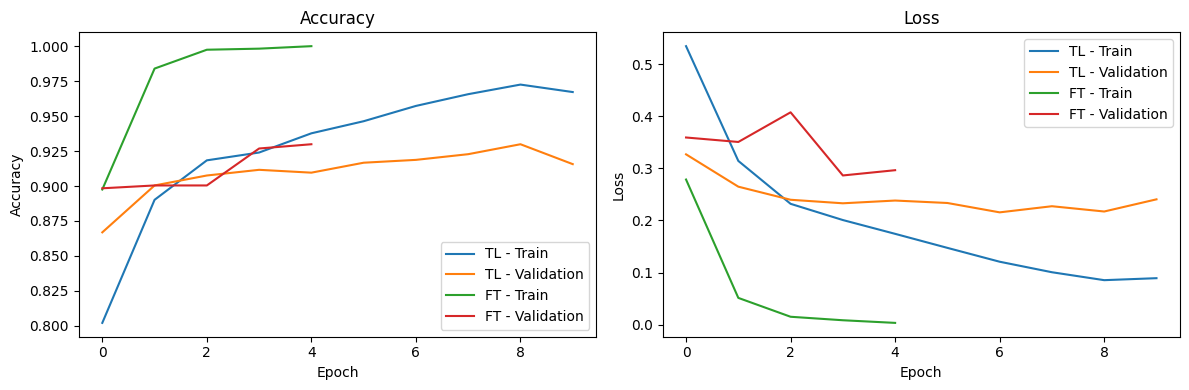

46/47 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.8958 - loss: 0.3101

2026-10-22 21:24:03.797279: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 21:24:03.934801: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


47/47 ━━━━━━━━━━━━━━━━━━━━ 80s 2s/step - accuracy: 0.9079 - loss: 0.2847
Test Loss : 0.2847
Test Accuracy : 0.9079
47/47 ━━━━━━━━━━━━━━━━━━━━ 11s 139ms/step


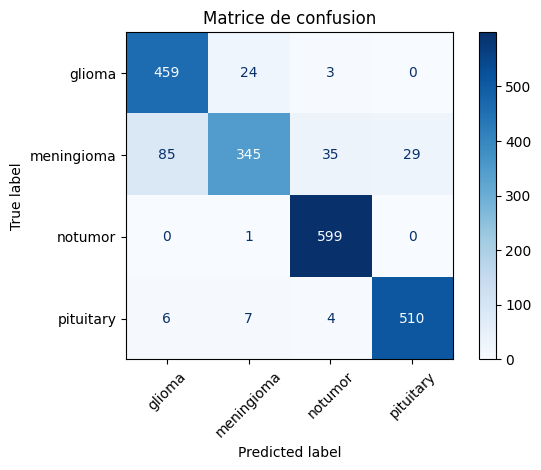

In [19]:
build_transfer_model(
    base_model=MobileNetV2,
    normalize_collback=preprocess_input,
    x_train=X_train,
    y_train = y_train,
    x_val = X_val,
    y_val = y_val,
    x_test = X_test,
    y_test = y_test
)